<a href="https://colab.research.google.com/github/pradityaputra888-lab/latihan-machine-learning/blob/main/pertemuan10/Bab10_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 10 — Clustering: K-Means, Hierarchical, dan DBSCAN

**Dataset:** data pelanggan sintetis (Praktikum 10.1–10.6) dan data pelanggan bergaya *Mall Customer* (Latihan) · **Isi notebook:** Praktikum 10.1–10.6 (kode modul), Latihan 1 (Elbow & Silhouette), dan Latihan 2 (Praktikum 10.7: tiga algoritma pada dataset yang sama).

> Jalankan sel dari atas ke bawah secara berurutan.

## 10.11 Implementasi Python

### Praktikum 10.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

print("Library berhasil dimuat.")

Library berhasil dimuat.


### Praktikum 10.2 Import Dataset
Dataset sintetis: simulasi data pelanggan (frekuensi belanja, nilai transaksi) dengan tiga kelompok.

In [2]:
rng = np.random.default_rng(42)
n = 300
X = np.vstack([
    rng.normal([5, 200000],  [1.5, 30000], (100, 2)),
    rng.normal([15, 800000], [2, 50000],   (100, 2)),
    rng.normal([2, 50000],   [0.8, 15000], (100, 2)),
])
print("Ukuran data:", X.shape)

Ukuran data: (300, 2)


### Praktikum 10.3 Preprocessing

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)   # Scaling WAJIB karena K-Means berbasis jarak

### Praktikum 10.4 Training Model

In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_kmeans = kmeans.fit_predict(X_scaled)

agglo = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels_agglo = agglo.fit_predict(X_scaled)

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

### Praktikum 10.5 Evaluasi

In [5]:
print("Silhouette Score K-Means      :", round(silhouette_score(X_scaled, labels_kmeans), 3))
print("Silhouette Score Agglomerative:", round(silhouette_score(X_scaled, labels_agglo), 3))
n_noise = (labels_dbscan == -1).sum()
print("Jumlah noise point (DBSCAN)   :", n_noise)

# Tambahan: jumlah cluster yang ditemukan DBSCAN dan ukuran tiap cluster
print("Jumlah cluster DBSCAN         :", len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0))
print("Ukuran tiap cluster DBSCAN    :", {int(k): int(v) for k, v in zip(*np.unique(labels_dbscan, return_counts=True))})

Silhouette Score K-Means      : 0.711
Silhouette Score Agglomerative: 0.709
Jumlah noise point (DBSCAN)   : 0
Jumlah cluster DBSCAN         : 2
Ukuran tiap cluster DBSCAN    : {0: 200, 1: 100}


### Praktikum 10.6 Visualisasi

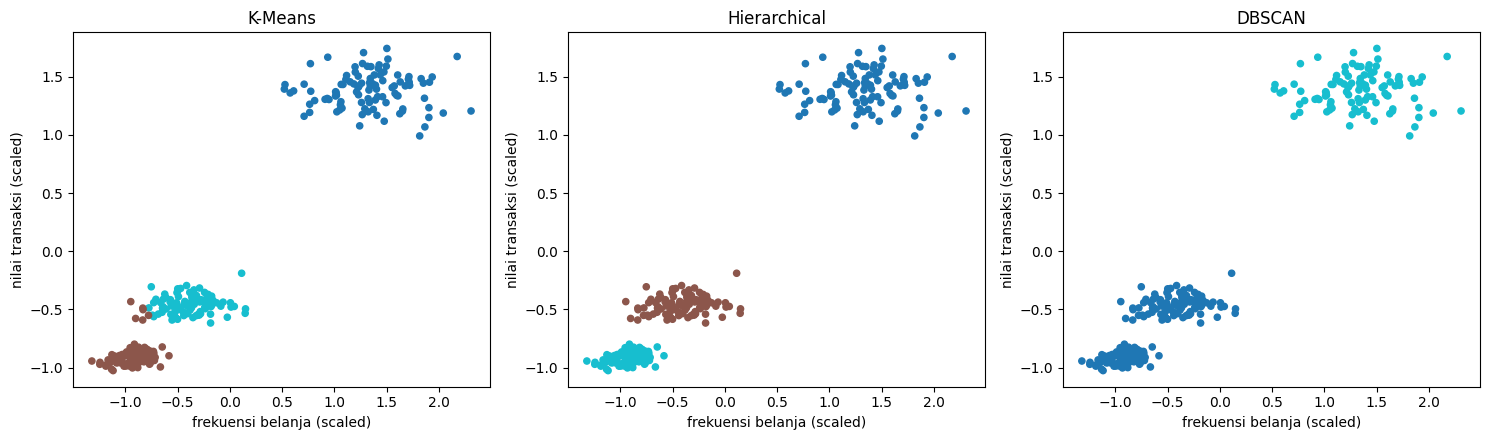

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, labels, judul in zip(axes,
                             [labels_kmeans, labels_agglo, labels_dbscan],
                             ["K-Means", "Hierarchical", "DBSCAN"]):
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap="tab10", s=20)
    ax.set_title(judul)
    ax.set_xlabel("frekuensi belanja (scaled)"); ax.set_ylabel("nilai transaksi (scaled)")
plt.tight_layout()
plt.show()

### Interpretasi (Praktikum 10.1–10.6)
- **Silhouette Score:** K-Means 0,711 dan Agglomerative 0,709, hampir identik dan cukup tinggi (>0,7), sehingga tiga kelompok pelanggan terpisah dengan baik pada data sintetis ini.
- **DBSCAN hanya menemukan 2 cluster** (ukuran 200 dan 100) dengan **0 noise point**, padahal data dibuat dari 3 kelompok. Pada `eps=0,3`, dua kelompok yang saling berdekatan di ruang ter-*scale* terhubung dan digabung menjadi satu cluster. Karena data berdistribusi normal tanpa pencilan, tidak ada pelanggan "tidak biasa" yang bisa ditandai sebagai noise (penjelasan modul tentang noise point baru relevan pada data yang memang punya pencilan; lihat Latihan 2).
- **Pelajaran:** K-Means dan Hierarchical memerlukan jumlah cluster ditentukan di awal, sedangkan DBSCAN menentukan sendiri jumlah cluster tetapi sangat bergantung pada `eps` dan `min_samples`. Silhouette yang tinggi tidak otomatis berarti segmentasinya benar, jadi selalu padukan dengan visualisasi dan pemahaman bisnis.

---
## 10.12 Latihan Praktikum

### Latihan 1 — Menentukan k Optimal
**Instruksi:** buat plot *Elbow Method* dan *Silhouette Score* untuk k = 2 sampai 10, lalu tentukan k optimal beserta justifikasinya.

**Dataset:** dataset *Mall Customer Segmentation* dari Kaggle harus diunduh manual, sehingga di sini dibuat **data sintetis bergaya Mall Customer**: 200 pelanggan dengan dua fitur (`pendapatan_tahunan_k` dalam ribu USD dan `skor_belanja` 1–100). Terdapat 5 segmen asli yang sedikit saling tumpang tindih, ditambah 6 pelanggan "tidak biasa" (*outlier*). Kolom `segmen_asli` **hanya dipakai untuk validasi di akhir**, tidak masuk ke proses clustering (pada data nyata label ini tidak tersedia).

In [7]:
rng = np.random.default_rng(42)
# (nama segmen, rata-rata pendapatan, rata-rata skor belanja, jumlah pelanggan)
definisi = [
    ("Pendapatan rendah - belanja rendah",   25, 20, 38),
    ("Pendapatan rendah - belanja tinggi",   25, 80, 38),
    ("Pendapatan sedang - belanja sedang",   55, 50, 50),
    ("Pendapatan tinggi - belanja rendah",   88, 17, 34),
    ("Pendapatan tinggi - belanja tinggi",   88, 82, 34),
]
bagian = [pd.DataFrame({"pendapatan_tahunan_k": rng.normal(inc, 11, m),
                        "skor_belanja": rng.normal(sp, 11, m),
                        "segmen_asli": nama}) for nama, inc, sp, m in definisi]
outlier = pd.DataFrame({"pendapatan_tahunan_k": [120, 125, 118, 10, 12, 60],
                        "skor_belanja":         [95,   5,  50,  95,  5, 98],
                        "segmen_asli": "Outlier"})
df_mall = pd.concat(bagian + [outlier], ignore_index=True)
df_mall[["pendapatan_tahunan_k", "skor_belanja"]] = df_mall[["pendapatan_tahunan_k", "skor_belanja"]].clip(1, 130)

fitur_mall = ["pendapatan_tahunan_k", "skor_belanja"]
Xm = StandardScaler().fit_transform(df_mall[fitur_mall])
print("Ukuran data:", df_mall.shape)
df_mall.head()

Ukuran data: (200, 3)


,pendapatan_tahunan_k,skor_belanja,segmen_asli
0,28.351888,10.930707,Pendapatan rendah - belanja rendah
1,13.560175,27.156521,Pendapatan rendah - belanja rendah
2,33.254963,28.175796,Pendapatan rendah - belanja rendah
3,35.346212,25.974697,Pendapatan rendah - belanja rendah
4,3.538613,12.679393,Pendapatan rendah - belanja rendah


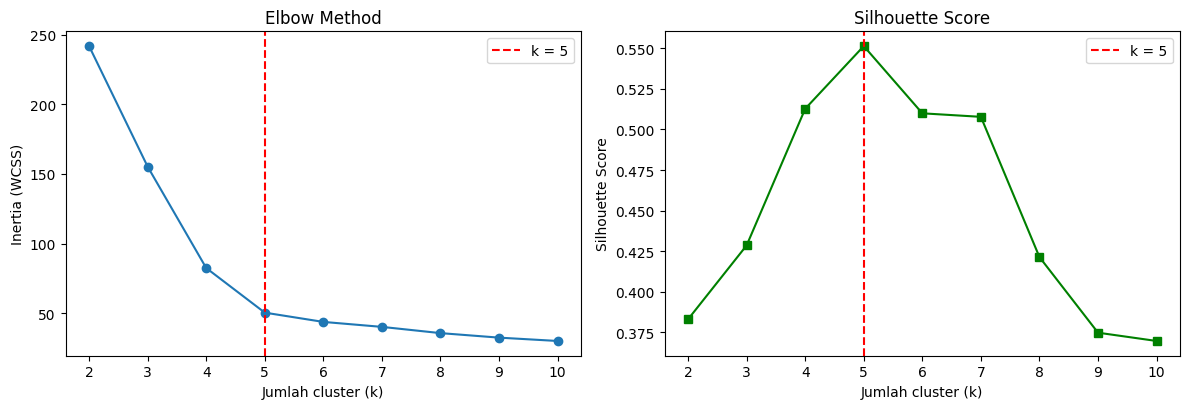

k optimal berdasarkan Silhouette tertinggi: 5


,k,Inertia,Silhouette,Davies-Bouldin (lebih kecil lebih baik),Penurunan inertia
0,2,241.707,0.383,1.150,NaN
1,3,155.236,0.429,0.753,-86.5
2,4,82.502,0.513,0.665,-72.7
3,5,50.490,0.551,0.592,-32.0
4,6,43.837,0.510,0.713,-6.7
5,7,40.271,0.508,0.678,-3.6
6,8,35.797,0.421,0.896,-4.5
7,9,32.559,0.375,0.997,-3.2
8,10,30.158,0.370,0.947,-2.4


In [8]:
from sklearn.metrics import davies_bouldin_score

rentang_k = list(range(2, 11))
inertia, sil, dbi = [], [], []
for k in rentang_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xm)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xm, km.labels_))
    dbi.append(davies_bouldin_score(Xm, km.labels_))

k_opt = rentang_k[int(np.argmax(sil))]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(rentang_k, inertia, "o-")
axes[0].axvline(k_opt, color="red", ls="--", label=f"k = {k_opt}")
axes[0].set_xlabel("Jumlah cluster (k)"); axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_title("Elbow Method"); axes[0].legend()

axes[1].plot(rentang_k, sil, "s-", color="green")
axes[1].axvline(k_opt, color="red", ls="--", label=f"k = {k_opt}")
axes[1].set_xlabel("Jumlah cluster (k)"); axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score"); axes[1].legend()
plt.tight_layout(); plt.show()

hasil_k = pd.DataFrame({"k": rentang_k, "Inertia": inertia, "Silhouette": sil, "Davies-Bouldin (lebih kecil lebih baik)": dbi})
hasil_k["Penurunan inertia"] = hasil_k["Inertia"].diff().round(1)
print("k optimal berdasarkan Silhouette tertinggi:", k_opt)
hasil_k.round(3)

**Kesimpulan Latihan 1 (k optimal dan justifikasi):**

**k optimal = 5.**

| k | 2 | 3 | 4 | **5** | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|
| Silhouette | 0,383 | 0,429 | 0,513 | **0,551** | 0,510 | 0,508 | 0,421 | 0,375 | 0,370 |
| Davies-Bouldin | 1,150 | 0,753 | 0,665 | **0,592** | 0,713 | 0,678 | 0,896 | 0,997 | 0,947 |

**Justifikasi:**
1. **Elbow Method:** penurunan inertia sangat besar sampai k=5 (241,7 → 155,2 → 82,5 → 50,5), lalu melandai tajam (k=6 hanya turun 6,7, dan penambahan berikutnya hanya 2–5). Tekukan siku berada di **k=5**.
2. **Silhouette Score** mencapai puncak di **k=5 (0,551)**. Nilai 0,51–0,70 menandakan struktur cluster yang cukup jelas.
3. **Davies-Bouldin Index** (makin kecil makin baik) juga terendah di k=5 (0,592), sehingga tiga indikator menunjuk angka yang sama.
4. **Masuk akal secara bisnis:** lima segmen sesuai kuadran pendapatan × belanja ditambah segmen tengah, dan masing-masing dapat diberi strategi pemasaran berbeda. k=4 menggabungkan dua segmen yang sebenarnya berbeda, sedangkan k≥6 memecah segmen alami tanpa makna bisnis tambahan dan menurunkan kualitas cluster.

**Catatan kehati-hatian:** silhouette k=5, 6, dan 7 cukup berdekatan (0,551 / 0,510 / 0,508), jadi pilihan akhir sebaiknya dikuatkan oleh elbow dan interpretasi bisnis, bukan satu metrik saja. Pada data sintetis ini jawaban sebenarnya memang 5 segmen (dikonfirmasi pada Latihan 2 dengan ARI).

### Latihan 2 — Segmentasi dengan Tiga Algoritma (Praktikum 10.7)
**Instruksi:** terapkan K-Means, Hierarchical (Agglomerative), dan DBSCAN pada dataset yang sama; bandingkan jumlah cluster dan Silhouette Score; visualisasikan ketiganya dalam satu figure; tulis analisis mana yang paling masuk akal secara bisnis.

Dataset yang dipakai adalah `df_mall` dari Latihan 1. Untuk DBSCAN, `eps` dipilih lewat uji beberapa nilai karena algoritma ini sangat sensitif terhadap parameter tersebut.

In [9]:
# Praktikum 10.7 — langkah 1: tuning eps pada DBSCAN (min_samples=5)
baris = []
for eps in [0.2, 0.25, 0.3, 0.35, 0.4, 0.5]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(Xm)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    ok = lab != -1
    s = silhouette_score(Xm[ok], lab[ok]) if n_cl > 1 else np.nan
    baris.append({"eps": eps, "Jumlah cluster": n_cl, "Noise": int((~ok).sum()), "Silhouette (tanpa noise)": s})
pd.DataFrame(baris).round(3)

,eps,Jumlah cluster,Noise,Silhouette (tanpa noise)
0,0.20,7,101,0.565
1,0.25,6,57,0.579
2,0.30,4,25,0.536
3,0.35,4,10,0.514
4,0.40,1,5,NaN
5,0.50,1,3,NaN


In [10]:
# Praktikum 10.7 — langkah 2: terapkan ketiga algoritma
from sklearn.metrics import adjusted_rand_score

K = 5   # dari Latihan 1
labels_km = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(Xm)
labels_ag = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xm)
labels_db = DBSCAN(eps=0.35, min_samples=5).fit_predict(Xm)

def ringkas(nama, lab):
    ok = lab != -1
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    return {"Algoritma": nama,
            "Jumlah cluster": n_cl,
            "Noise": int((~ok).sum()),
            "Silhouette": round(silhouette_score(Xm[ok], lab[ok]), 3) if n_cl > 1 else np.nan,
            "ARI vs segmen asli": round(adjusted_rand_score(df_mall["segmen_asli"], lab), 3)}

tabel_banding = pd.DataFrame([ringkas("K-Means (k=5)", labels_km),
                              ringkas("Hierarchical / Ward (k=5)", labels_ag),
                              ringkas("DBSCAN (eps=0.35, min_samples=5)", labels_db)])
tabel_banding

,Algoritma,Jumlah cluster,Noise,Silhouette,ARI vs segmen asli
0,K-Means (k=5),5,0,0.551,0.897
1,Hierarchical / Ward (k=5),5,0,0.528,0.823
2,"DBSCAN (eps=0.35, min_samples=5)",4,10,0.514,0.665


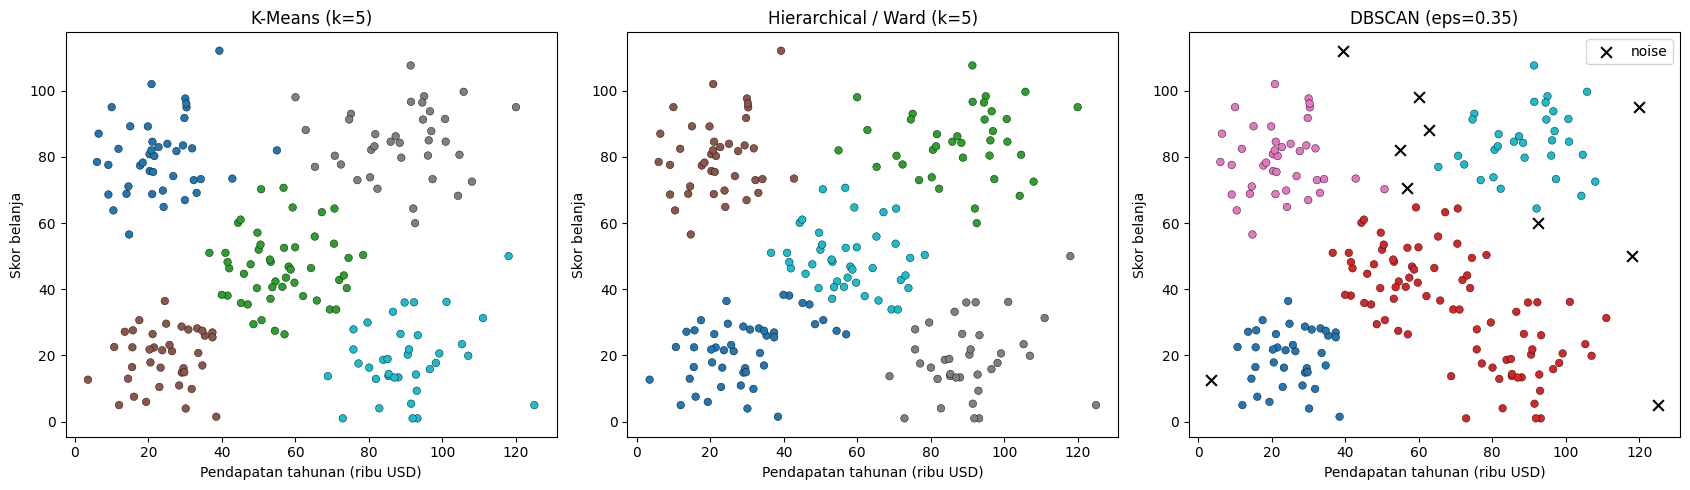

In [11]:
# Visualisasi tiga algoritma berdampingan (sumbu dalam satuan asli agar mudah dibaca)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, lab, judul in zip(axes, [labels_km, labels_ag, labels_db],
                          ["K-Means (k=5)", "Hierarchical / Ward (k=5)", "DBSCAN (eps=0.35)"]):
    ok = lab != -1
    ax.scatter(df_mall.loc[ok, fitur_mall[0]], df_mall.loc[ok, fitur_mall[1]], c=lab[ok], cmap="tab10", s=30, edgecolors="k", linewidths=0.3)
    if (~ok).any():
        ax.scatter(df_mall.loc[~ok, fitur_mall[0]], df_mall.loc[~ok, fitur_mall[1]], c="black", marker="x", s=60, label="noise")
        ax.legend()
    ax.set_title(judul)
    ax.set_xlabel("Pendapatan tahunan (ribu USD)"); ax.set_ylabel("Skor belanja")
plt.tight_layout(); plt.show()

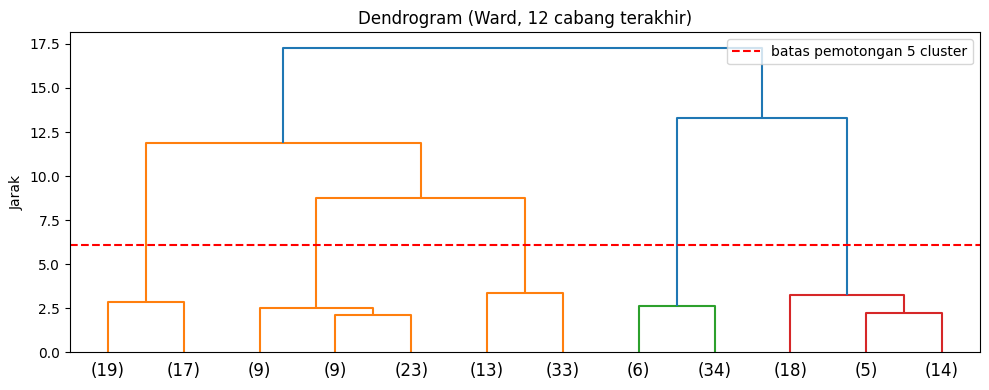

In [12]:
# Dendrogram (dipotong pada 5 cluster) untuk memperkuat pembacaan hasil Hierarchical
Z = linkage(Xm, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=12, show_leaf_counts=True)
plt.axhline(y=(Z[-5, 2] + Z[-4, 2]) / 2, color="red", ls="--", label="batas pemotongan 5 cluster")
plt.title("Dendrogram (Ward, 12 cabang terakhir)"); plt.ylabel("Jarak"); plt.legend()
plt.tight_layout(); plt.show()

In [13]:
# Profil bisnis tiap segmen hasil K-Means (satuan asli)
def beri_nama(inc, sp):
    lv_inc = "rendah" if inc < 40 else ("sedang" if inc < 70 else "tinggi")
    lv_sp  = "rendah" if sp < 40 else ("sedang" if sp <= 60 else "tinggi")
    return f"Pendapatan {lv_inc}, belanja {lv_sp}"

profil = (df_mall.assign(cluster=labels_km)
          .groupby("cluster")
          .agg(jumlah=("cluster", "size"),
               rata_pendapatan=(fitur_mall[0], "mean"),
               rata_skor_belanja=(fitur_mall[1], "mean")))
profil["Nama segmen"] = [beri_nama(a, b) for a, b in zip(profil["rata_pendapatan"], profil["rata_skor_belanja"])]
profil.sort_values("rata_pendapatan").round(1)

,jumlah,rata_pendapatan,rata_skor_belanja,Nama segmen
cluster,,,,
0,41,23.0,80.2,"Pendapatan rendah, belanja tinggi"
2,38,24.5,19.4,"Pendapatan rendah, belanja rendah"
1,49,56.1,46.4,"Pendapatan sedang, belanja sedang"
3,36,88.7,84.3,"Pendapatan tinggi, belanja tinggi"
4,36,90.7,19.1,"Pendapatan tinggi, belanja rendah"


**Analisis Latihan 2:**

| Algoritma | Jumlah cluster | Noise | Silhouette | ARI vs segmen asli |
|---|---|---|---|---|
| K-Means (k=5) | 5 | 0 | **0,551** | **0,897** |
| Hierarchical / Ward (k=5) | 5 | 0 | 0,528 | 0,823 |
| DBSCAN (eps=0,35) | 4 | 10 | 0,514* | 0,665 |

\*Silhouette DBSCAN dihitung tanpa titik noise. ARI (*Adjusted Rand Index*) hanya bisa dihitung karena ini data sintetis dengan label asli; pada data nyata, pembanding semacam ini tidak ada.

**Analisis per algoritma**
- **K-Means paling masuk akal secara bisnis.** Silhouette tertinggi, paling mirip dengan segmen sebenarnya, setiap pelanggan masuk ke satu segmen dengan ukuran seimbang (36–49 pelanggan), dan hasilnya langsung bisa dibaca sebagai profil pelanggan.
- **Hierarchical hasilnya mirip tetapi sedikit lebih rendah.** Titik di perbatasan antar segmen dikelompokkan berbeda. Keunggulannya ada pada dendrogram: lonjakan jarak penggabungan setelah 5 cluster (3,4 → 8,8) mengonfirmasi k=5 tanpa harus menebak. Kelemahannya, komputasi membesar cepat pada data besar.
- **DBSCAN sensitif dan di sini kurang cocok sebagai segmentasi utama.** Pada tabel `eps`: 0,2 menghasilkan 7 cluster dengan 101 noise (separuh pelanggan), 0,3–0,35 menghasilkan 4 cluster, dan 0,4 menggabungkan semuanya menjadi 1 cluster. Pada `eps=0,35`, segmen "pendapatan sedang" dan "pendapatan tinggi–belanja rendah" menyatu karena tidak ada celah kepadatan di antara keduanya. Kekuatannya terlihat pada **10 titik noise**: pelanggan di tepi sebaran atau berperilaku ekstrem (mis. pendapatan sangat tinggi dengan belanja sangat rendah, atau skor belanja hampir maksimal pada pendapatan menengah) yang layak ditinjau secara terpisah.

**Profil segmen K-Means dan saran strategi**

| Segmen | Jumlah | Rata-rata pendapatan (ribu USD) | Rata-rata skor belanja | Strategi |
|---|---|---|---|---|
| Pendapatan rendah, belanja tinggi | 41 | 23,0 | 80,2 | Program loyalitas, cicilan, promo produk terjangkau |
| Pendapatan rendah, belanja rendah | 38 | 24,5 | 19,4 | Diskon dan produk hemat; prioritas rendah |
| Pendapatan sedang, belanja sedang | 49 | 56,1 | 46,4 | Segmen inti (terbesar): *cross-sell* dan *upsell* |
| Pendapatan tinggi, belanja tinggi | 36 | 88,7 | 84,3 | Pelanggan VIP: layanan prioritas dan produk premium |
| Pendapatan tinggi, belanja rendah | 36 | 90,7 | 19,1 | **Potensi terbesar yang belum tergarap:** penawaran personal dan produk premium |

**Kesimpulan:** gunakan **K-Means (k=5)** sebagai segmentasi utama, dan **DBSCAN sebagai pelengkap** untuk menandai pelanggan tidak biasa yang perlu ditinjau manual (VIP khusus, anomali, atau kesalahan data). Angka segmen di atas bisa sedikit berubah di Colab Anda; strukturnya tetap sama.